# 06. Experimento de aumentos fotométricos durante el fine-tuning

Proyecto: clasificación de defectos superficiales de palta Hass (PICADURA / RUSSET).

Este notebook es una nueva prueba experimental, independiente de `resnet50.ipynb`. Parte de los archivos generados por `D1_s42_03` y compara una nueva variante con `FT_D1_s42_03`. No modifica las imágenes TIFF ni sobrescribe entrenamientos anteriores.

Estado inicial: **experimento no ejecutado**. Las métricas del nuevo método aparecerán solamente después de realizar el entrenamiento y la evaluación. Utilice el kernel `palta_gpu (CUDA)` en Ubuntu WSL2.

## 1. Pregunta y diseño experimental

¿Incorporar variaciones suaves de brillo y contraste a **ambas clases durante el fine-tuning** mejora el desempeño de ResNet50 frente a FT_D1?

| Elemento | FT_D1 (referencia) | FT_D1_PHOTO (nuevo) |
|---|---|---|
| Punto de partida | D1_s42_03, pesos ImageNet + cabeza D1 | Exactamente el mismo checkpoint D1_s42_03 |
| Entrenamiento elegible | 572 TIFF completos, sin fragmentar vistas | Los mismos 572 TIFF |
| Copias adicionales | 77 copias RUSSET según plan D1 | Las mismas 77 copias RUSSET |
| Aumentos adicionales por época | Ninguno | Brillo 0.95–1.05 y contraste 0.95–1.05 en PICADURA y RUSSET |
| Resolución | 256 × 512 (alto × ancho) | 256 × 512 |
| Capas actualizables | `conv5`, BatchNormalization congelada | Igual |
| Optimizador y tasa inicial | Adam, 1e-5 | Igual |
| Lote, épocas máximas, semilla | 1, 8, 42 | Igual |
| Validación | 127 imágenes sin aumento | Las mismas 127, sin aumento |
| Test | Reservado | Reservado |

El factor fotométrico se aplica sobre los píxeles válidos usando la máscara de relleno devuelta por `ajustar_tamano`; el relleno no se altera. Las tres franjas y el orden horizontal de vistas permanecen intactos. Las variaciones nuevas se vuelven a generar en cada pasada, mediante una semilla reproducible.

Se conservarán los mismos controles de parada y selección de pesos mediante `val_loss`. El cambio deliberado es la política fotométrica de entrenamiento. La diferencia observada será exploratoria, no una prueba estadística concluyente; pequeñas diferencias numéricas entre corridas y el número reducido de RUSSET en validation limitan la inferencia.

## 2. Instrucciones de uso

1. Colocar este archivo en `6. entrenamiento` dentro de `PROYECTO_TI_2` y abrirlo desde VS Code en **WSL: Ubuntu**.
2. Seleccionar el kernel `palta_gpu (CUDA)` de Python 3.12.
3. Ejecutar las celdas en orden hasta la sección 9. Las primeras secciones leen configuraciones, preparan funciones y verifican el protocolo, pero **no entrenan**.
4. Revisar la sección 9: `EJECUTAR_EXPERIMENTO = False` viene desactivado. Cambiar a `True` solamente cuando se hayan confirmado todos los controles y el nuevo nombre de corrida esté libre.
5. Al finalizar, volver a `False` y guardar. La sección 10 permite comparar los resultados guardados.

El dataset permanece fuera del repositorio. Este notebook solo genera nuevos resultados bajo `7. resultados/entrenamiento/FT_D1_PHOTO_s42_01/` si se activa expresamente la ejecución. Si esa carpeta existe, se detendrá antes de sobrescribirla.

In [1]:
from pathlib import Path, PureWindowsPath
import hashlib
import importlib.metadata
import json
import os
import platform
import random
import sys
import time

import numpy as np
import pandas as pd
from IPython.display import display

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "README.md").is_file()
             and (p / "utilidades_imagenes.py").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abra este notebook desde la carpeta de PROYECTO_TI_2.")
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from utilidades_imagenes import (
    encontrar_raiz, resolver_dataset, listar_imagenes,
    crear_dataset_tf, cargar_rgb, ajustar_tamano,
)
RAIZ = encontrar_raiz()
RUTA_DATASET_RELATIVA = "../DATASET_PALTA"
DATASET = resolver_dataset(RAIZ, RUTA_DATASET_RELATIVA)
SALIDA = RAIZ / "7. resultados" / "entrenamiento"
SEMILLA = 42
TAMANO = (256, 512)  # alto, ancho
TAMANO_ENTRADA = TAMANO  # compatible con la firma de construir_modelo de resnet50.ipynb
CLASES = ["PICADURA", "RUSSET"]
RUN_ORIGEN = "D1_s42_03"
RUN_REFERENCIA = "FT_D1_s42_03"
os.environ.setdefault("KERAS_HOME", str(RAIZ / ".cache" / "keras"))

print("Proyecto:", RAIZ)
print("Dataset disponible:", DATASET.is_dir())
print("Python:", sys.executable)
print("Corrida de partida:", RUN_ORIGEN)
print("Referencia para comparar:", RUN_REFERENCIA)

Proyecto: /mnt/c/Users/TCI_AUTO/Documents/Maestría UNI/4_2. Proyecto de Invetigación  2/PROYECTO_TI_2
Dataset disponible: True
Python: /home/tci_auto/.venvs/palta_gpu/bin/python
Corrida de partida: D1_s42_03
Referencia para comparar: FT_D1_s42_03


## 3. Comprobar las corridas guardadas

La variante parte de la **cabeza entrenada de D1**, no del checkpoint final de FT_D1. De este modo, ambos ensayos de fine-tuning parten del mismo punto de inicio y mantienen la comparación más controlada.

In [2]:
CARPETA_ORIGEN = SALIDA / RUN_ORIGEN
CARPETA_REFERENCIA = SALIDA / RUN_REFERENCIA

requeridos = [
    CARPETA_ORIGEN / "configuracion.json",
    CARPETA_ORIGEN / "metricas_validation.json",
    CARPETA_ORIGEN / "mejor_cabeza.weights.h5",
    CARPETA_ORIGEN / "copias_russet_train.csv",
    CARPETA_REFERENCIA / "configuracion.json",
    CARPETA_REFERENCIA / "metricas_validation.json",
    CARPETA_REFERENCIA / "mejor_finetune.weights.h5",
]
faltantes = [str(p.relative_to(RAIZ)) for p in requeridos if not p.is_file()]
if faltantes:
    raise FileNotFoundError("Faltan resultados anteriores:\n" + "\n".join(faltantes))

config_origen = json.loads((CARPETA_ORIGEN / "configuracion.json").read_text(encoding="utf-8"))
config_referencia = json.loads((CARPETA_REFERENCIA / "configuracion.json").read_text(encoding="utf-8"))
metricas_origen = json.loads((CARPETA_ORIGEN / "metricas_validation.json").read_text(encoding="utf-8"))
metricas_referencia = json.loads((CARPETA_REFERENCIA / "metricas_validation.json").read_text(encoding="utf-8"))

if (config_origen.get("condicion") != "D1" or
        config_origen.get("copias_russet_por_fruto") != 1 or
        tuple(config_origen.get("tamano_entrada", ())) != TAMANO):
    raise ValueError("D1 no coincide con la configuracion del experimento.")
if (config_referencia.get("origen") != RUN_ORIGEN or
        config_referencia.get("condicion") != "FT_D1"):
    raise ValueError("FT_D1 no utiliza el origen esperado.")
for met in (metricas_origen, metricas_referencia):
    if met.get("estado") != "completo" or met.get("particion") != "validation":
        raise ValueError("La evaluacion anterior no esta completa.")

print("Origen D1:", RUN_ORIGEN)
print("Referencia FT_D1:", RUN_REFERENCIA)
print("Metricas de FT_D1 (validation):")
display(pd.DataFrame([{
    "accuracy": metricas_referencia["accuracy"],
    "macro_f1": metricas_referencia["macro_f1"],
    "recall_russet": metricas_referencia["recall_russet"],
}]).round(4))
print("No se ha creado ningun modelo nuevo.")

Origen D1: D1_s42_03
Referencia FT_D1: FT_D1_s42_03
Metricas de FT_D1 (validation):


,accuracy,macro_f1,recall_russet
0,0.874,0.7524,0.5238


No se ha creado ningun modelo nuevo.


## 4. Auditoría del dataset

Se reutilizan sin modificar las comprobaciones de `resnet50.ipynb`: firma del inventario, coincidencias por bytes y píxeles, cuatro exclusiones lógicas y verificación SHA-256 de los archivos. La revisión completa de los 829 hashes se realiza **antes de iniciar un entrenamiento**.

La auditoría también comprueba la partición `test` solo a efectos de integridad. No se calculan predicciones ni métricas sobre `test`.

In [4]:
def hash_archivo(ruta):
    calculo = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            calculo.update(bloque)
    return calculo.hexdigest()


def firma_tabla(tabla):
    texto = "\n".join(tabla["archivo"] + ":" + tabla["sha256"])
    return hashlib.sha256(texto.encode()).hexdigest()


def leer_auditoria():
    carpeta = RAIZ / "7. resultados" / "eda"
    resumen = json.loads((carpeta / "eda_resumen.json").read_text(encoding="utf-8-sig"))
    inventario = pd.read_csv(carpeta / "eda_inventario.csv", encoding="utf-8-sig", keep_default_na=False)
    duplicados = pd.read_csv(carpeta / "eda_duplicados.csv", encoding="utf-8-sig", keep_default_na=False)
    columnas = {"archivo", "sha256", "sha_pixeles", "particion", "clase", "imagen", "error"}
    if not columnas.issubset(inventario.columns):
        raise ValueError("El inventario no contiene la auditoria necesaria.")
    if inventario.empty or inventario["archivo"].duplicated().any():
        raise ValueError("El inventario esta vacio o contiene rutas repetidas.")
    if len(inventario) != resumen["archivos"] or len(inventario) != resumen["imagenes"]:
        raise ValueError("Los conteos no coinciden. Revise el EDA.")
    if resumen["corruptas"] or inventario["error"].ne("").any():
        raise ValueError("El EDA registra errores de lectura.")
    if not inventario["imagen"].astype(str).str.lower().isin(["true", "1"]).all():
        raise ValueError("El inventario incluye archivos no reconocidos como imagenes.")
    if firma_tabla(inventario) != resumen["sha256_dataset"]:
        raise ValueError("La firma del inventario no coincide con el resumen.")
    for campo in ("sha256", "sha_pixeles"):
        if not inventario[campo].astype(str).str.fullmatch(r"[0-9a-f]{64}").all():
            raise ValueError(f"Hashes incompletos en {campo}.")
    for registro in inventario.itertuples(index=False):
        ruta = Path(registro.archivo)
        win = PureWindowsPath(registro.archivo)
        if (ruta.is_absolute() or win.drive or win.root or ".." in ruta.parts
                or "\\" in registro.archivo or len(ruta.parts) < 3):
            raise ValueError("El inventario debe usar rutas relativas dentro del dataset.")
        if ruta.parts[:2] != (registro.particion, registro.clase):
            raise ValueError(f"Ruta y etiqueta incoherentes: {registro.archivo}")
        if registro.particion not in {"train", "validation", "test"}:
            raise ValueError("Particion no reconocida.")
        if registro.clase not in {"PICADURA", "RUSSET"}:
            raise ValueError("Clase no reconocida.")

    requeridas = {"tipo", "archivo", "archivo_coincidente", "particion",
                  "particion_coincidente", "clase", "clase_coincidente"}
    if not requeridas.issubset(duplicados.columns):
        raise ValueError("El reporte de duplicados esta incompleto.")
    exactos = duplicados[duplicados["tipo"].isin(["bytes_exactos", "pixeles_exactos"])]
    indexado = inventario.set_index("archivo")
    pares_fuga, pares_conflicto, excluidos = set(), set(), set()
    for fila in exactos.itertuples(index=False):
        a, b = fila.archivo, fila.archivo_coincidente
        if a == b or a not in indexado.index or b not in indexado.index:
            raise ValueError("El reporte de duplicados contiene una ruta invalida.")
        ra, rb = indexado.loc[a], indexado.loc[b]
        if (ra.particion, rb.particion, ra.clase, rb.clase) != (
                fila.particion, fila.particion_coincidente, fila.clase, fila.clase_coincidente):
            raise ValueError("Duplicados e inventario no coinciden.")
        clave = "sha256" if fila.tipo == "bytes_exactos" else "sha_pixeles"
        if ra[clave] != rb[clave]:
            raise ValueError("El par reportado no coincide con los hashes del inventario.")
        par = tuple(sorted([a, b]))
        fuga, conflicto = ra.particion != rb.particion, ra.clase != rb.clase
        if fuga:
            pares_fuga.add(par)
        if conflicto:
            pares_conflicto.add(par)
        if fuga or conflicto:
            excluidos.update([a, b])
    if (len(pares_fuga) != resumen["pares_exactos_entre_particiones"]
            or len(pares_conflicto) != resumen["pares_exactos_etiquetas_distintas"]):
        raise ValueError("Los conteos de pares no coinciden con el resumen.")

    elegibles = inventario.loc[~inventario["archivo"].isin(excluidos)].copy()
    for clave in ("sha256", "sha_pixeles"):
        grupos = elegibles.groupby(clave)[["particion", "clase"]].nunique()
        if (grupos > 1).any().any():
            raise ValueError("Persisten duplicados entre particiones o clases. Revise el EDA.")
    return resumen, inventario, sorted(excluidos)


def verificar_auditoria(dataset, aprobar_exclusiones=False):
    resumen, inventario, excluidos = leer_auditoria()
    dataset = Path(dataset).resolve()
    rutas = set(inventario["archivo"])
    locales = {p.relative_to(dataset).as_posix() for p in dataset.rglob("*") if p.is_file()}
    if locales != rutas:
        raise RuntimeError("El contenido del dataset cambio. Revise las rutas y actualice el EDA.")
    total = len(inventario)
    for numero, registro in enumerate(inventario.itertuples(index=False), 1):
        ruta = (dataset / registro.archivo).resolve()
        if not ruta.is_relative_to(dataset):
            raise ValueError("Un enlace apunta fuera del dataset.")
        if hash_archivo(ruta) != registro.sha256:
            raise RuntimeError(f"Archivo distinto al auditado: {registro.archivo}")
        if numero % 100 == 0 or numero == total:
            print(f"Integridad: {numero}/{total}")
    if excluidos and not aprobar_exclusiones:
        raise RuntimeError(
            "Integridad correcta; falta aprobar las exclusiones mostradas en la seccion 8. "
            "No se entreno ni se modificaron imagenes."
        )
    elegibles = inventario.loc[~inventario["archivo"].isin(excluidos)].sort_values("archivo")
    return {
        "sha256_dataset": resumen["sha256_dataset"],
        "sha256_manifiesto": firma_tabla(elegibles),
        "exclusiones": excluidos,
        "archivos_originales": int(len(inventario)),
        "archivos_elegibles": int(len(elegibles)),
        "alcance": "Integridad exacta; independencia por fruto/lote pendiente de trazabilidad.",
    }

In [5]:
# Consulta del manifiesto: todavia no lee todos los TIFF.
resumen_eda, inventario_eda, excluidos_eda = leer_auditoria()
print("Archivos auditados en EDA:", len(inventario_eda))
print("Exclusiones lógicas propuestas:", len(excluidos_eda))
print("Elegibles esperados:", len(inventario_eda) - len(excluidos_eda))
print("Dataset e inventario compatibles por firma historica:",
      resumen_eda["sha256_dataset"] == config_origen["protocolo_comun"]["sha256_dataset"])
assert resumen_eda["sha256_dataset"] == config_origen["protocolo_comun"]["sha256_dataset"]
assert sorted(excluidos_eda) == sorted(config_origen["exclusiones"])
print("La integridad local SHA-256 se comprobara de nuevo al iniciar la corrida.")

Archivos auditados en EDA: 829
Exclusiones lógicas propuestas: 4
Elegibles esperados: 825
Dataset e inventario compatibles por firma historica: True
La integridad local SHA-256 se comprobara de nuevo al iniciar la corrida.


## 5. Copias de D1 y transformación fotométrica

Estas funciones se conservan del notebook original. La nueva política fotométrica **no sustituye** las 77 copias de RUSSET: se aplica adicionalmente a cada muestra del entrenamiento (PICADURA y RUSSET). El cálculo de la máscara mantiene sin cambios el color de relleno.

In [6]:
def plan_copias_russet(tabla_train, copias, semilla=SEMILLA):
    """Registra copias de los frutos RUSSET sin alterar el inventario."""
    if not isinstance(copias, int) or copias < 0 or copias > 3:
        raise ValueError("Use entre 0 y 3 copias por fruto.")
    russet = tabla_train.loc[tabla_train["clase"] == "RUSSET", "archivo"].tolist()
    filas = []
    for archivo in russet:
        for numero in range(1, copias + 1):
            clave = f"{semilla}|{archivo}|{numero}".encode("utf-8")
            entero = int.from_bytes(hashlib.sha256(clave).digest()[:8], "big")
            rng = np.random.default_rng(entero)
            filas.append({"archivo": archivo, "copia": numero, "etiqueta": 1,
                          "brillo": float(rng.uniform(0.92, 1.08)),
                          "contraste": float(rng.uniform(0.90, 1.10))})
    return pd.DataFrame(filas, columns=["archivo", "copia", "etiqueta", "brillo", "contraste"])


def aplicar_cambio_fotometrico(matriz, mascara, brillo, contraste):
    """Cambia la intensidad y el contraste sin mover pixeles ni modificar el relleno."""
    matriz = np.asarray(matriz, dtype=np.float32)
    mascara = np.asarray(mascara, dtype=bool)
    if matriz.ndim != 3 or matriz.shape[-1] != 3 or mascara.shape != matriz.shape[:2]:
        raise ValueError("Revise las dimensiones RGB y la mascara.")
    if not (0.85 <= brillo <= 1.15 and 0.85 <= contraste <= 1.15):
        raise ValueError("El cambio solicitado esta fuera del rango previsto.")
    resultado = matriz.copy()
    if mascara.any():
        pixeles = matriz[mascara]
        media = pixeles.mean(axis=0)
        resultado[mascara] = np.clip((pixeles - media) * contraste * brillo + media * brillo, 0, 255)
    return resultado




def pesos_para_etiquetas(etiquetas, clases):
    """Calcula class_weight con la distribucion efectiva de cada condicion."""
    from sklearn.utils.class_weight import compute_class_weight
    etiquetas = np.asarray(etiquetas, dtype=np.int32)
    valores = np.arange(len(clases), dtype=np.int32)
    if set(np.unique(etiquetas)) != set(valores):
        raise ValueError("El entrenamiento debe conservar ambas clases.")
    pesos = compute_class_weight("balanced", classes=valores, y=etiquetas)
    return {int(k): float(v) for k, v in zip(valores, pesos)}

In [7]:
# Verificación del plan original D1 sin copiar ni editar TIFF.
tabla_train_pre = listar_imagenes(DATASET, "train", clases=CLASES)
tabla_train_pre = tabla_train_pre.loc[
    ~tabla_train_pre["archivo"].isin(excluidos_eda)
].reset_index(drop=True)
plan_reproducido = plan_copias_russet(tabla_train_pre, 1, SEMILLA)
plan_guardado = pd.read_csv(CARPETA_ORIGEN / "copias_russet_train.csv")
pd.testing.assert_frame_equal(
    plan_reproducido.reset_index(drop=True),
    plan_guardado.reset_index(drop=True),
    check_exact=False, rtol=1e-11, atol=1e-12,
)
if len(plan_guardado) != 77:
    raise ValueError("La cantidad de copias D1 no coincide con el protocolo.")

print("Train elegible:", len(tabla_train_pre))
print("Copias RUSSET D1:", len(plan_guardado))
print("Muestras totales por época:", len(tabla_train_pre) + len(plan_guardado))
print("Plan D1 reproducido y validado sin modificaciones.")

Train elegible: 572
Copias RUSSET D1: 77
Muestras totales por época: 649
Plan D1 reproducido y validado sin modificaciones.


## 6. Nuevo flujo: brillo y contraste suaves durante el entrenamiento

En cada época se realiza lo siguiente:

1. Leer cada TIFF completo de la partición `train` y aplicar el mismo ajuste de tamaño que D1.
2. Para las 77 copias de RUSSET, reproducir su transformación fotométrica fija de D1.
3. Aplicar una variación nueva en el rango 0.95–1.05 para brillo y contraste en **ambas clases**, distinta en cada pasada y con semilla reproducible.
4. Devolver el tensor RGB `float32` en 0–255. El preprocesamiento de ResNet50 sigue dentro del modelo.

Se usa `.repeat()` y `steps_per_epoch` explícitos para no agotar el dataset durante las épocas. Los factores no se aplican a `validation` ni a `test`.

In [8]:
BRILLO_EXTRA = (0.95, 1.05)
CONTRASTE_EXTRA = (0.95, 1.05)


def construir_manifiesto_entrenamiento(tabla_train, plan):
    base = tabla_train[["archivo", "etiqueta"]].copy()
    base["copia"] = 0
    base["brillo_d1"] = 1.0
    base["contraste_d1"] = 1.0
    extras = plan.rename(columns={"brillo": "brillo_d1", "contraste": "contraste_d1"})[
        ["archivo", "etiqueta", "copia", "brillo_d1", "contraste_d1"]
    ].copy()
    manifiesto = pd.concat([base, extras], ignore_index=True)
    if manifiesto["archivo"].isna().any():
        raise ValueError("El manifiesto incluye rutas vacias.")
    if not set(manifiesto["etiqueta"]) == {0, 1}:
        raise ValueError("El entrenamiento debe incluir PICADURA y RUSSET.")
    return manifiesto


def factores_para_visita(indice_global, archivo, semilla=SEMILLA):
    clave = f"{semilla}|{int(indice_global)}|{archivo}".encode("utf-8")
    entero = int.from_bytes(hashlib.sha256(clave).digest()[:8], "big")
    generador = np.random.default_rng(entero)
    brillo = float(generador.uniform(*BRILLO_EXTRA))
    contraste = float(generador.uniform(*CONTRASTE_EXTRA))
    return brillo, contraste


def crear_train_fotometrico(manifiesto, dataset, tamano=TAMANO, lote=1, semilla=SEMILLA):
    """Genera nuevas variaciones por visita usando mascaras reales de relleno."""
    import tensorflow as tf
    if lote != 1:
        raise ValueError("Para comparar con FT_D1, mantener LOTE_FT = 1.")
    tamano = tuple(map(int, tamano))
    dataset = Path(dataset)
    if manifiesto.empty:
        raise ValueError("El entrenamiento esta vacio.")

    archivos = manifiesto["archivo"].astype(str).tolist()
    etiquetas = manifiesto["etiqueta"].to_numpy(dtype=np.int32)
    copias = manifiesto["copia"].to_numpy(dtype=np.int32)
    brillos = manifiesto["brillo_d1"].to_numpy(dtype=np.float32)
    contrastes = manifiesto["contraste_d1"].to_numpy(dtype=np.float32)

    secuencia = tf.data.Dataset.from_tensor_slices(
        (archivos, etiquetas, copias, brillos, contrastes)
    )
    secuencia = secuencia.shuffle(
        buffer_size=len(manifiesto), seed=semilla, reshuffle_each_iteration=True
    ).repeat().enumerate()

    def cargar_y_transformar(indice, ruta_relativa, etiqueta, copia, brillo_d1, contraste_d1):
        ruta_bytes = ruta_relativa.item() if hasattr(ruta_relativa, "item") else ruta_relativa
        ruta = ruta_bytes.decode("utf-8") if isinstance(ruta_bytes, bytes) else str(ruta_bytes)
        imagen = cargar_rgb(dataset / ruta)
        rgb, mascara = ajustar_tamano(imagen, tamano)
        rgb = np.asarray(rgb, dtype=np.float32)
        mascara = np.asarray(mascara, dtype=bool)
        if int(copia) > 0:
            rgb = aplicar_cambio_fotometrico(
                rgb, mascara, float(brillo_d1), float(contraste_d1)
            )
        brillo, contraste = factores_para_visita(int(indice), ruta, semilla)
        rgb = aplicar_cambio_fotometrico(rgb, mascara, brillo, contraste)
        if not np.isfinite(rgb).all():
            raise ValueError(f"La imagen transformada contiene valores invalidos: {ruta}")
        return rgb.astype(np.float32), np.int32(etiqueta)

    def mapear(indice, registro):
        ruta, etiqueta, copia, brillo_d1, contraste_d1 = registro
        imagen, clase = tf.numpy_function(
            cargar_y_transformar,
            [indice, ruta, etiqueta, copia, brillo_d1, contraste_d1],
            Tout=[tf.float32, tf.int32]
        )
        imagen.set_shape((*tamano, 3))
        clase.set_shape(())
        return imagen, clase

    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 2
    opciones.experimental_deterministic = True
    secuencia = secuencia.with_options(opciones)
    return secuencia.map(mapear, num_parallel_calls=1).batch(lote).prefetch(1)

## 7. Construcción de ResNet50

Se utiliza la misma arquitectura del notebook principal: ResNet50 preentrenada, `preprocess_input` aplicado una sola vez, pooling promedio, Dropout(0.35) y Dense softmax. Se cargan los pesos de la cabeza del experimento D1; después se habilita exclusivamente `conv5` (sin actualizar BatchNormalization).

In [9]:
def construir_modelo(numero_clases, tamano=TAMANO_ENTRADA,
                      volteo_horizontal=False, semilla=SEMILLA, pesos="imagenet"):
    import tensorflow as tf
    from tensorflow.keras.applications.resnet50 import preprocess_input

    if numero_clases < 2:
        raise ValueError("El clasificador necesita al menos dos clases.")
    tf.keras.utils.set_random_seed(semilla)
    entrada = tf.keras.Input(shape=(*tamano, 3), dtype="float32", name="imagen_rgb")
    x = entrada
    if volteo_horizontal:
        x = tf.keras.layers.RandomFlip("horizontal", seed=semilla, name="aumento_train")(x)
    x = tf.keras.layers.Lambda(preprocess_input, name="preprocesamiento_resnet50")(x)
    modelo_base = tf.keras.applications.ResNet50(
        input_shape=(*tamano, 3), include_top=False, weights=pesos, pooling="avg",
    )
    modelo_base.trainable = False
    x = modelo_base(x, training=False)
    x = tf.keras.layers.Dropout(0.35, seed=semilla)(x)
    salida = tf.keras.layers.Dense(
        numero_clases, activation="softmax", name="clase",
        kernel_initializer=tf.keras.initializers.GlorotUniform(seed=semilla),
    )(x)
    modelo = tf.keras.Model(entrada, salida, name="resnet50_palta")
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy", metrics=["accuracy"],
    )
    return modelo

## 8. Entrenamiento, validación y guardado de resultados

La nueva corrida se identifica con un nombre exclusivo. No se permite escribir encima de `D1_s42_03` ni `FT_D1_s42_03`.

Durante el entrenamiento se guardan `configuracion.json`, `auditoria.json`, `historial.csv`, `estado.json` y el mejor checkpoint. Luego se evalúa únicamente `validation`: métricas globales, métricas por clase, predicciones por archivo y matriz de confusión.

In [10]:
def ejecutar_experimento_fotometrico(repeticion="01", epocas=8, lote_ft=1,
                                    tasa=1e-5, aprobar_exclusiones=False):
    import tensorflow as tf
    if not (1 <= int(epocas) <= 25 and lote_ft == 1 and 0 < float(tasa) <= 1e-4):
        raise ValueError("Revise epocas, lote (1) y tasa.")
    if not (repeticion.isdigit() and len(repeticion) <= 4):
        raise ValueError("Use un identificador numerico corto para la repeticion.")
    destino = SALIDA / f"FT_D1_PHOTO_s{SEMILLA}_{repeticion}"
    if destino.exists():
        raise FileExistsError("La carpeta de resultados ya existe. Cambie REPETICION sin borrarla.")
    if not aprobar_exclusiones:
        raise RuntimeError("Debe autorizar expresamente las cuatro exclusiones auditadas.")

    # Verificación de todos los hashes e identidad de los conjuntos usados en D1.
    auditoria = verificar_auditoria(DATASET, aprobar_exclusiones=True)
    protocolo = config_origen["protocolo_comun"]
    if (auditoria["sha256_dataset"] != protocolo["sha256_dataset"] or
            auditoria["sha256_manifiesto"] != protocolo["sha256_manifiesto"] or
            sorted(auditoria["exclusiones"]) != sorted(config_origen["exclusiones"])):
        raise RuntimeError("Los datos no coinciden con la corrida D1 de origen.")

    tabla_train = listar_imagenes(DATASET, "train", clases=CLASES)
    tabla_val = listar_imagenes(DATASET, "validation", clases=CLASES)
    tabla_train = tabla_train.loc[
        ~tabla_train["archivo"].isin(auditoria["exclusiones"])
    ].reset_index(drop=True)
    tabla_val = tabla_val.loc[
        ~tabla_val["archivo"].isin(auditoria["exclusiones"])
    ].reset_index(drop=True)
    if len(tabla_train) != config_origen["n_train"] or len(tabla_val) != config_origen["n_validation"]:
        raise RuntimeError("Cambió el número de imágenes elegibles.")
    if set(tabla_train["clase"]) != set(CLASES) or set(tabla_val["clase"]) != set(CLASES):
        raise ValueError("Falta una clase en el conjunto de entrenamiento o validación.")

    plan = plan_copias_russet(tabla_train, 1, SEMILLA)
    plan_previo = pd.read_csv(CARPETA_ORIGEN / "copias_russet_train.csv")
    pd.testing.assert_frame_equal(plan, plan_previo, check_exact=False, atol=1e-12, rtol=1e-11)
    manifiesto = construir_manifiesto_entrenamiento(tabla_train, plan)
    if len(manifiesto) != config_origen["n_train_efectivo"]:
        raise RuntimeError("El entrenamiento efectivo no coincide con D1.")
    pesos_fit = pesos_para_etiquetas(manifiesto["etiqueta"].to_numpy(), CLASES)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEMILLA)
    try:
        tf.config.experimental.enable_op_determinism()
    except (AttributeError, RuntimeError):
        pass
    gpus = tf.config.list_physical_devices("GPU")
    if not gpus:
        raise RuntimeError("No se detectó GPU. Seleccione el kernel palta_gpu (CUDA) en WSL2.")
    print("GPU disponible:", gpus[0].name)

    modelo = construir_modelo(len(CLASES), TAMANO, False, SEMILLA)
    entrada_cabeza = tf.keras.Input(shape=(int(modelo.layers[-2].input.shape[-1]),))
    salida_cabeza = modelo.layers[-1](modelo.layers[-2](entrada_cabeza))
    cabeza = tf.keras.Model(entrada_cabeza, salida_cabeza)
    cabeza.load_weights(str(CARPETA_ORIGEN / "mejor_cabeza.weights.h5"))

    base = next(capa for capa in modelo.layers if isinstance(capa, tf.keras.Model))
    base.trainable = True
    for capa in base.layers:
        capa.trainable = capa.name.startswith("conv5_") and not isinstance(
            capa, tf.keras.layers.BatchNormalization
        )
    activas = sum(int(capa.trainable) for capa in base.layers)
    if activas < 1:
        raise RuntimeError("No se encontraron capas ajustables en conv5.")
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=float(tasa)),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    train = crear_train_fotometrico(manifiesto, DATASET, TAMANO, lote_ft, SEMILLA)
    validation = crear_dataset_tf(
        tabla_val, DATASET, tamano=TAMANO, tamano_lote=lote_ft,
        entrenamiento=False, semilla=SEMILLA,
    )

    configuracion = {
        "condicion": "FT_D1_PHOTO",
        "origen": RUN_ORIGEN,
        "referencia": RUN_REFERENCIA,
        "nombre_ejecucion": destino.name,
        "tamano_entrada": list(TAMANO),
        "clases": CLASES,
        "n_train_original": len(tabla_train),
        "n_train_efectivo": len(manifiesto),
        "n_validation": len(tabla_val),
        "copias_russet_por_fruto": 1,
        "aumento_adicional": {
            "brillo": list(BRILLO_EXTRA), "contraste": list(CONTRASTE_EXTRA),
            "ambas_clases": True, "por_visita": True, "mantiene_relleno": True,
            "aplicado_solo_en": "train",
        },
        "protocolo_comun": {
            "tamano_lote": int(lote_ft), "epocas_maximas": int(epocas),
            "learning_rate": float(tasa), "bloque_ajustado": "conv5",
            "batch_normalization": "congelada", "semilla": SEMILLA,
            "sha256_dataset": auditoria["sha256_dataset"],
            "sha256_manifiesto": auditoria["sha256_manifiesto"],
        },
        "exclusiones": auditoria["exclusiones"],
        "pesos_fit": pesos_fit,
        "versiones": {
            p: importlib.metadata.version(p)
            for p in ("numpy", "pandas", "Pillow", "tensorflow", "scikit-learn")
        },
        "python": platform.python_version(),
    }
    firma = hashlib.sha256(json.dumps(configuracion, sort_keys=True).encode()).hexdigest()
    configuracion["firma_protocolo"] = firma

    destino.mkdir(parents=True, exist_ok=False)
    (destino / "configuracion.json").write_text(
        json.dumps(configuracion, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    (destino / "auditoria.json").write_text(
        json.dumps(auditoria, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    plan.to_csv(destino / "copias_russet_train.csv", index=False)
    manifiesto.to_csv(destino / "manifiesto_train.csv", index=False)
    estado = destino / "estado.json"
    estado.write_text(json.dumps({"estado": "iniciado"}), encoding="utf-8")
    inicio = time.perf_counter()

    try:
        callbacks = [
            tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4,
                                             restore_best_weights=True),
            tf.keras.callbacks.ModelCheckpoint(
                str(destino / "mejor_finetune.weights.h5"),
                monitor="val_loss", save_best_only=True, save_weights_only=True,
            ),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2),
            tf.keras.callbacks.CSVLogger(str(destino / "historial.csv")),
            tf.keras.callbacks.TerminateOnNaN(),
        ]
        historial = modelo.fit(
            train, steps_per_epoch=len(manifiesto),
            validation_data=validation, epochs=int(epocas),
            class_weight=pesos_fit, callbacks=callbacks,
        )
        checkpoint = destino / "mejor_finetune.weights.h5"
        if not checkpoint.is_file():
            raise RuntimeError("No se generó el checkpoint del mejor modelo.")
        modelo.load_weights(str(checkpoint))
        mejor_epoca = int(np.argmin(historial.history["val_loss"])) + 1
        estado.write_text(json.dumps({
            "estado": "entrenamiento_completo",
            "epocas": len(historial.history["loss"]),
            "mejor_epoca_val_loss": mejor_epoca,
            "segundos_entrenamiento": round(time.perf_counter() - inicio, 2),
        }, indent=2), encoding="utf-8")
    except (Exception, KeyboardInterrupt) as error:
        estado.write_text(json.dumps({
            "estado": "incompleto", "detalle": str(error),
            "traceback": __import__("traceback").format_exc(),
        }, indent=2), encoding="utf-8")
        raise

    return {
        "modelo": modelo, "historial": historial, "carpeta": destino,
        "configuracion": configuracion, "auditoria": auditoria,
        "clases": CLASES, "tamano_entrada": TAMANO,
        "semilla": SEMILLA, "tabla_val": tabla_val,
    }

In [11]:
def evaluar_validacion_fotometrica(experimento):
    import matplotlib.pyplot as plt
    from sklearn.metrics import (
        accuracy_score, f1_score, recall_score, precision_score,
        balanced_accuracy_score, classification_report,
        confusion_matrix, ConfusionMatrixDisplay,
    )
    tabla = experimento["tabla_val"].reset_index(drop=True)
    clases = experimento["clases"]
    modelo = experimento["modelo"]
    validation = crear_dataset_tf(
        tabla, DATASET, tamano=TAMANO, tamano_lote=1,
        entrenamiento=False, semilla=SEMILLA,
    )
    probabilidades = np.asarray(modelo.predict(validation, verbose=0))
    if probabilidades.shape != (len(tabla), len(clases)) or not np.isfinite(probabilidades).all():
        raise RuntimeError("Las predicciones no tienen forma o valores válidos.")
    verdaderas = tabla["etiqueta"].to_numpy(dtype=np.int32)
    predichas = np.argmax(probabilidades, axis=1)
    clases_indice = np.arange(len(clases))
    informe = classification_report(
        verdaderas, predichas, labels=clases_indice, target_names=clases,
        output_dict=True, zero_division=0,
    )
    metricas = {
        "estado": "completo", "particion": "validation",
        "n_imagenes": len(tabla),
        "condicion": "FT_D1_PHOTO",
        "nombre_ejecucion": experimento["carpeta"].name,
        "firma_protocolo": experimento["configuracion"]["firma_protocolo"],
        "accuracy": float(accuracy_score(verdaderas, predichas)),
        "macro_f1": float(f1_score(verdaderas, predichas,
                                   average="macro", zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(verdaderas, predichas)),
        "recall_picadura": float(informe["PICADURA"]["recall"]),
        "recall_russet": float(informe["RUSSET"]["recall"]),
        "precision_russet": float(informe["RUSSET"]["precision"]),
        "f1_russet": float(informe["RUSSET"]["f1-score"]),
    }
    carpeta = experimento["carpeta"]
    (carpeta / "metricas_validation.json").write_text(
        json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    pd.DataFrame(informe).transpose().to_csv(
        carpeta / "metricas_por_clase_validation.csv"
    )
    resultados = tabla[["archivo", "clase", "etiqueta"]].copy()
    resultados["prediccion"] = [clases[int(i)] for i in predichas]
    for indice, clase in enumerate(clases):
        resultados[f"probabilidad_{clase}"] = probabilidades[:, indice]
    resultados.to_csv(carpeta / "predicciones_validation.csv", index=False)
    matriz = confusion_matrix(verdaderas, predichas, labels=clases_indice)
    pd.DataFrame(matriz, index=clases, columns=clases).to_csv(
        carpeta / "matriz_confusion_validation.csv"
    )
    grafico = ConfusionMatrixDisplay(matriz, display_labels=clases).plot()
    grafico.ax_.set_title("FT_D1_PHOTO - validation")
    grafico.figure_.tight_layout()
    grafico.figure_.savefig(carpeta / "matriz_confusion_validation.png", dpi=150)
    plt.show()
    plt.close(grafico.figure_)
    print("Métricas FT_D1_PHOTO:")
    display(pd.DataFrame(informe).transpose().round(4))
    return metricas, resultados


def graficar_curvas_fotometricas(historial, carpeta):
    import matplotlib.pyplot as plt
    datos = historial.history
    for variable in ("loss", "accuracy"):
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(datos[variable], label="train")
        ax.plot(datos["val_" + variable], label="validation")
        ax.set_xlabel("Época")
        ax.set_ylabel(variable)
        ax.set_title("FT_D1_PHOTO - " + variable)
        ax.legend()
        fig.tight_layout()
        fig.savefig(carpeta / f"curva_{variable}.png", dpi=150)
        plt.show()
        plt.close(fig)

## 9. Control de ejecución

Esta es la **única celda que inicia el entrenamiento**. Por seguridad, está desactivada de inicio. Si no aparece ningún error en las comprobaciones previas, revisar que `palta_gpu (CUDA)` detecte la GPU y activar solo esta celda.

No usar `Run All` con `EJECUTAR_EXPERIMENTO = True`; una vez concluido el entrenamiento, volver inmediatamente a `False` y guardar el notebook.

I0000 00:00:1792987635.221601  122514 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792987635.274783  122514 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792987636.979051  122514 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Integridad: 100/829
Integridad: 200/829
Integridad: 300/829
Integridad: 400/829
Integridad: 500/829
Integridad: 600/829
Integridad: 700/829
Integridad: 800/829
Integridad: 829/829
GPU disponible: /physical_device:GPU:0


I0000 00:00:1792987661.582871  122514 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5561 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070 Ti Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Epoch 1/8


/home/tci_auto/.venvs/palta_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1792987673.943977  125197 cuda_dnn.cc:461] Loaded cuDNN version 92700


649/649 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.8613 - loss: 0.3223

E0000 00:00:1792987737.587765  122514 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_4}}


649/649 ━━━━━━━━━━━━━━━━━━━━ 82s 116ms/step - accuracy: 0.8613 - loss: 0.3223 - val_accuracy: 0.7323 - val_loss: 0.5221 - learning_rate: 1.0000e-05
Epoch 2/8
649/649 ━━━━━━━━━━━━━━━━━━━━ 75s 116ms/step - accuracy: 0.9060 - loss: 0.2316 - val_accuracy: 0.8583 - val_loss: 0.3888 - learning_rate: 1.0000e-05
Epoch 3/8
649/649 ━━━━━━━━━━━━━━━━━━━━ 75s 115ms/step - accuracy: 0.9368 - loss: 0.1736 - val_accuracy: 0.8504 - val_loss: 0.3602 - learning_rate: 1.0000e-05
Epoch 4/8
649/649 ━━━━━━━━━━━━━━━━━━━━ 93s 143ms/step - accuracy: 0.9414 - loss: 0.1762 - val_accuracy: 0.8661 - val_loss: 0.3530 - learning_rate: 1.0000e-05
Epoch 5/8
649/649 ━━━━━━━━━━━━━━━━━━━━ 91s 140ms/step - accuracy: 0.9461 - loss: 0.1551 - val_accuracy: 0.8740 - val_loss: 0.3118 - learning_rate: 1.0000e-05
Epoch 6/8
649/649 ━━━━━━━━━━━━━━━━━━━━ 76s 117ms/step - accuracy: 0.9661 - loss: 0.0865 - val_accuracy: 0.8976 - val_loss: 0.4082 - learning_rate: 1.0000e-05
Epoch 7/8
649/649 ━━━━━━━━━━━━━━━━━━━━ 77s 119ms/step - accura

E0000 00:00:1792988314.628029  122514 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_4}}


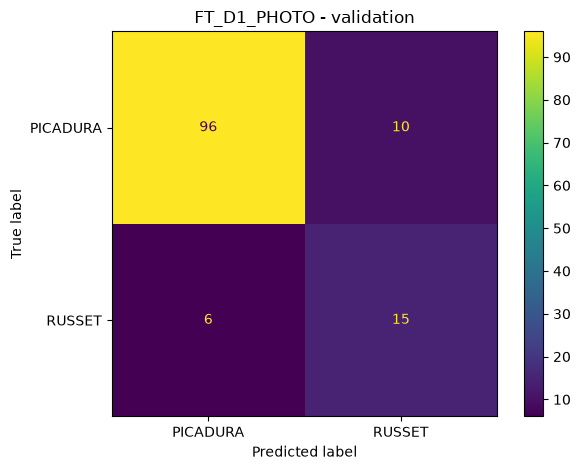

Métricas FT_D1_PHOTO:


,precision,recall,f1-score,support
PICADURA,0.9412,0.9057,0.9231,106.000
RUSSET,0.6000,0.7143,0.6522,21.000
accuracy,0.8740,0.8740,0.8740,0.874
macro avg,0.7706,0.8100,0.7876,127.000
weighted avg,0.8848,0.8740,0.8783,127.000


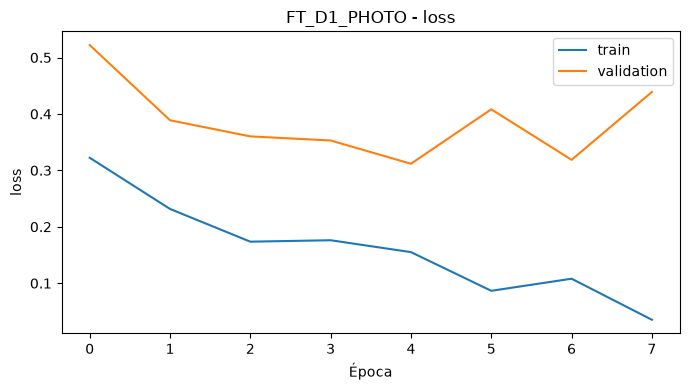

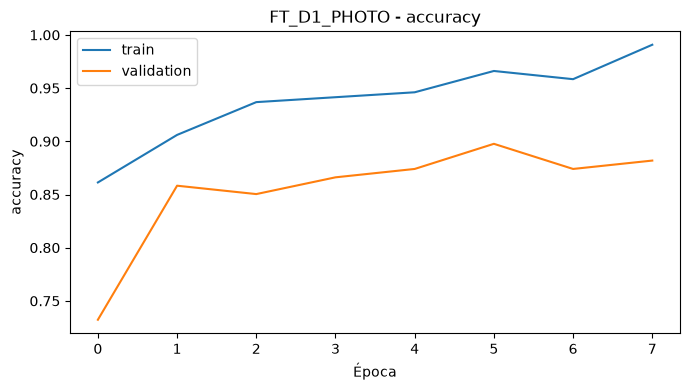

Corrida completada: 7. resultados/entrenamiento/FT_D1_PHOTO_s42_01
Volver a dejar EJECUTAR_EXPERIMENTO = False antes de guardar.


In [ ]:
EJECUTAR_EXPERIMENTO = False
REPETICION = "01"
EPOCAS_FT = 8
LOTE_FT = 1
TASA_FT = 1e-5
APROBAR_EXCLUSIONES = True

nombre_salida = f"FT_D1_PHOTO_s{SEMILLA}_{REPETICION}"
if EJECUTAR_EXPERIMENTO:
    experimento = ejecutar_experimento_fotometrico(
        repeticion=REPETICION,
        epocas=EPOCAS_FT,
        lote_ft=LOTE_FT,
        tasa=TASA_FT,
        aprobar_exclusiones=APROBAR_EXCLUSIONES,
    )
    metricas_nuevas, predicciones_nuevas = evaluar_validacion_fotometrica(experimento)
    graficar_curvas_fotometricas(experimento["historial"], experimento["carpeta"])
    print("Corrida completada:", experimento["carpeta"].relative_to(RAIZ))
    print("Volver a dejar EJECUTAR_EXPERIMENTO = False antes de guardar.")
else:
    print("Modo seguro. Experimento preparado:", nombre_salida)
    print("No se ha entrenado ni alterado el dataset.")

## 10. Comparación con FT_D1 sobre validation

La tabla se construye leyendo los archivos JSON guardados. Si el experimento nuevo no terminó, se mostrará como pendiente. No se rellenan métricas con valores simulados.

Criterio principal: Macro-F1. También se comparan el recall y la precisión de RUSSET, la exactitud y la matriz de confusión. Con 21 RUSSET en validación, un acierto equivale a 4.76 puntos porcentuales de recall; las diferencias pequeñas deben interpretarse con precaución.

In [14]:
nuevo = SALIDA / f"FT_D1_PHOTO_s{SEMILLA}_{REPETICION}"
archivo_nuevo = nuevo / "metricas_validation.json"
filas = []
for nombre, ruta in [("FT_D1", CARPETA_REFERENCIA / "metricas_validation.json"),
                     ("FT_D1_PHOTO", archivo_nuevo)]:
    if ruta.is_file():
        datos = json.loads(ruta.read_text(encoding="utf-8"))
        if datos.get("estado") != "completo" or datos.get("particion") != "validation":
            raise RuntimeError("Métricas incompletas en " + nombre)
        filas.append({"condicion": nombre, "estado": "completo",
                      "accuracy": float(datos["accuracy"]),
                      "macro_f1": float(datos["macro_f1"]),
                      "recall_russet": float(datos["recall_russet"])})
    else:
        filas.append({"condicion": nombre, "estado": "pendiente"})
comparativa = pd.DataFrame(filas)
display(comparativa.round(4))
if len(comparativa) == 2 and comparativa["estado"].eq("completo").all():
    print("Diferencia Macro-F1 (PHOTO - FT_D1):",
          round(comparativa.loc[1, "macro_f1"] - comparativa.loc[0, "macro_f1"], 4))
else:
    print("Todavía no hay métricas nuevas. El experimento sigue pendiente.")

,condicion,estado,accuracy,macro_f1,recall_russet
0,FT_D1,completo,0.874,0.7524,0.5238
1,FT_D1_PHOTO,completo,0.874,0.7876,0.7143


Diferencia Macro-F1 (PHOTO - FT_D1): 0.0352


## 11. Conclusiones previstas y límites

Al terminar el experimento se debe informar el resultado, sea mejor o peor que FT_D1. Se debe diferenciar entre una mejora numérica en `validation` y una mejora generalizable a paltas nuevas.

- No se cambia el orden de cámaras y vistas. Cada TIFF completo se mantiene como unidad de clasificación.
- No se aplican aumentos a validation ni test. Los conjuntos conservan las cuatro exclusiones del EDA.
- La independencia entre archivos del mismo fruto, lote o sesión aún requiere trazabilidad adicional.
- Una sola semilla y 21 RUSSET en validación no demuestran significancia estadística.
- El conjunto test permanece reservado hasta fijar el protocolo y revisar la selección del modelo.
- Una comparación más sólida requerirá repeticiones adicionales y revisión de errores por un especialista en calidad de fruta.

Este notebook registra la propuesta y, al ejecutarse, guardará la evidencia reproducible correspondiente; no presenta resultados del nuevo experimento antes de haberlos obtenido.